In [47]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

In [48]:
df = pd.read_csv('/content/tyre_pressure_2024.csv')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2921 entries, 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Data columns (total 1 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Tyre_Pressure_PSI  2921 non-null   float64
dtypes: float64(1)
memory usage: 45.6 KB


In [50]:
import numpy as np
import pandas as pd

def create_features(df):
    """
    Enhances the tyre-pressure DataFrame with various time-based,
    cyclical, and lag/rolling features.

    Assumptions:
    1) df.index is a DateTimeIndex at hourly frequency.
    2) The main column is 'tyre_pressure' in PSI.
    """
    # ------------------------------------------------------------------
    # 1. Basic Time-Based Features
    # ------------------------------------------------------------------
    df["Hour"] = df.index.hour
    df["DayOfWeek"] = df.index.dayofweek  # Monday=0, Sunday=6
    df["Month"] = df.index.month

    # Weekend and Rush Hour flags (example logic)
    df["isWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)
    df["isRushHour"] = df["Hour"].apply(lambda x: 1 if 7 <= x <= 9 or 17 <= x <= 19 else 0)

    # ------------------------------------------------------------------
    # 2. Cyclical Encoding for Hour, Day of Week, Month
    # ------------------------------------------------------------------
    df['hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

    df['day_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
    df['day_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

    df['month_sin'] = np.sin(2 * np.pi * (df['Month'] - 1) / 12)
    df['month_cos'] = np.cos(2 * np.pi * (df['Month'] - 1) / 12)

    # ------------------------------------------------------------------
    # 3. Lag and Rolling Features (using tyre_pressure)
    # ------------------------------------------------------------------
    # 24-hour lag (yesterday at the same hour)
    df['tp_lag_24h'] = df['Tyre_Pressure_PSI'].shift(24)

    # 72-hour rolling average (~3 days)
    df['tp_rolling_avg_3d'] = df['Tyre_Pressure_PSI'].rolling(window=72).mean()

    # ------------------------------------------------------------------
    # 4. Cleanup: Drop Unwanted Columns & Rows with NaNs
    # ------------------------------------------------------------------
    # We drop the raw Hour/DayOfWeek/Month columns now that we've
    # extracted cyclical features
    df.drop(['Hour', 'DayOfWeek', 'Month'], axis=1, inplace=True)

    # Drop any rows that became NaN due to shift or rolling
    df.dropna(inplace=True)

    return df


In [51]:
# Apply feature engineering function
df = create_features(df)

# Define features and target (replacing Engine_Temperature with tyre_pressure)
features = ['Tyre_Pressure_PSI', 'isWeekend', 'isRushHour',
            'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
            'month_sin', 'month_cos', 'tp_lag_24h',
            'tp_rolling_avg_3d']

# Define the target variable (the value we want to predict)
target = 'Tyre_Pressure_PSI'

In [52]:
train_size = int(len(df) * 0.1)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

In [53]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

In [54]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size - 8):  # Predict 8 readings (24 hours ahead)
        X.append(data[i:i+window_size])
        y.append(data[i+window_size:i+window_size+8, 0])  # Next 8 pressure values
    return np.array(X), np.array(y)

In [55]:
window_size = 56  # 1 week lookback for 8 readings per day
X_train, y_train = create_sequences(train_scaled, window_size)
X_test, y_test = create_sequences(test_scaled, window_size)

In [56]:
from tensorflow.keras.layers import Bidirectional, BatchNormalization

model = Sequential([
    # Bidirectional LSTM to capture forward/backward patterns
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(window_size, len(features))),
    BatchNormalization(),  # Stabilizes training
    Dropout(0.2),  # Slightly higher dropout for regularization

    # Stacked LSTM with reduced units
    Bidirectional(LSTM(64, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Final LSTM layer
    LSTM(32),

    # Intermediate dense layer for non-linear mapping
    Dense(64, activation='relu'),
    Dropout(0.2),

    # Output layer for 24-hour prediction
    Dense(8)
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [57]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [59]:
from tensorflow.keras.callbacks import EarlyStopping

# Define EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model with early stopping
history = model.fit(X_train, y_train,
                    epochs=50,
                    batch_size=32,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[early_stopping])

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0152 - mae: 0.0979 - val_loss: 0.1260 - val_mae: 0.3451
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0196 - mae: 0.1083 - val_loss: 0.1215 - val_mae: 0.3397
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0166 - mae: 0.1015 - val_loss: 0.1362 - val_mae: 0.3611
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0165 - mae: 0.0994 - val_loss: 0.1145 - val_mae: 0.3291
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0145 - mae: 0.0947 - val_loss: 0.1044 - val_mae: 0.3123
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0157 - mae: 0.0986 - val_loss: 0.1103 - val_mae: 0.3204
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0148 - mae: 0.0953 - val_loss: 0.1033 - val_mae: 0.3095
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0140 - mae: 0.0938 - val_loss: 0.1395 - val_mae: 0.3664
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0143 - mae: 0.0933 - 

In [60]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}')

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0822 - mae: 0.2350
Test Loss: 0.0807, Test MAE: 0.2368


In [61]:
def inverse_scale_predictions(scaled_predictions, scaler, feature_index=0):
    """
    Inverse scale predictions for multi-step output.

    Args:
        scaled_predictions: Array of shape (n_samples, n_steps)
        scaler: Fitted MinMaxScaler object
        feature_index: Index of the target feature in the original data

    Returns:
        Array of shape (n_samples, n_steps) with inverse-scaled predictions
    """
    # Get the number of samples and steps
    n_samples, n_steps = scaled_predictions.shape

    # Create a dummy array with the same shape as the original data
    dummy = np.zeros((n_samples * n_steps, len(features)))

    # Fill the target feature column with the predictions
    dummy[:, feature_index] = scaled_predictions.flatten()

    # Inverse transform the dummy array
    inverse_scaled = scaler.inverse_transform(dummy)

    # Reshape back to (n_samples, n_steps)
    return inverse_scaled[:, feature_index].reshape(n_samples, n_steps)

In [62]:
# Make predictions
test_predictions = model.predict(X_test[:1])  # Predict first test sample
test_predictions = inverse_scale_predictions(test_predictions, scaler)

# Get the corresponding timestamps for the predictions
prediction_timestamps = test_df.index[window_size:window_size+24]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step


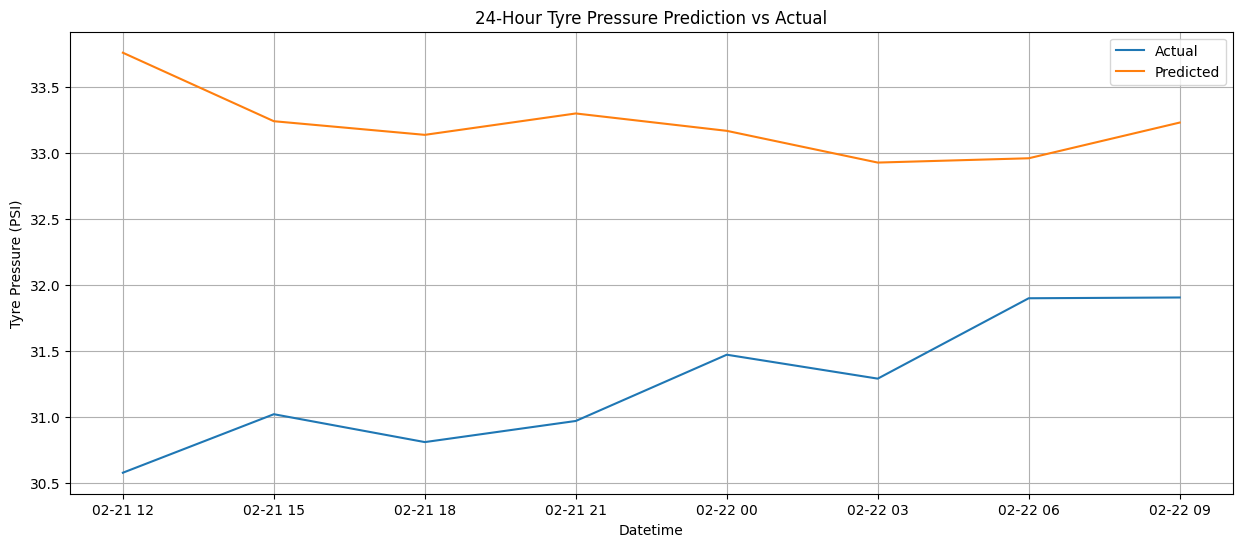

In [63]:
plt.figure(figsize=(15, 6))
plt.plot(test_df.index[window_size:window_size+8], test_df['Tyre_Pressure_PSI'].iloc[window_size:window_size+8], label='Actual')
plt.plot(test_df.index[window_size:window_size+8], test_predictions.flatten()[:8], label='Predicted')  # First 8 predictions
plt.title('24-Hour Tyre Pressure Prediction vs Actual')
plt.xlabel('Datetime')
plt.ylabel('Tyre Pressure (PSI)')
plt.legend()
plt.grid(True)
plt.show()


In [64]:
model.save("Final_TP_Prediction_Model.h5")

In [65]:
import pickle

with open('scaler_TP.pkl', 'wb') as f:
    pickle.dump(scaler, f)